# Pobreza monetaria e informalidad laboral en el Perú — **Hito 3**
### Revisión metodológica e implementación inicial: segmentación de distritos por clustering

Integrantes: Thiago Ormeño · Daniela Eléspuru &nbsp;|&nbsp; Curso: Data Mining &nbsp;|&nbsp; Universidad del Pacífico

---

**Qué responde este cuaderno.** Los programas de formalización laboral del MTPE se focalizan casi siempre con una sola cifra
(la tasa de informalidad). La pregunta del proyecto es **qué tipos de distrito existen según la estructura de su empleo y cómo se
relacionan con la pobreza monetaria**. Para responderla se agrupan los 1,270 distritos de la matriz analítica del Hito 2.

**Qué se compara.** Tres familias de técnicas (K-means, jerárquico aglomerativo y DBSCAN), cuatro representaciones de los datos
(11 variables estandarizadas, PCA de 2 y de 5 componentes, NMF de 3 factores) y varios valores de K, `eps` y `min_samples`.
La técnica seleccionada se decide **con la evidencia de las secciones 5 a 8**, no de antemano.

| Sección | Contenido | Exige el Hito 3 |
|---|---|---|
| 1 | Configuración y carga de la matriz analítica | carga reproducible |
| 2 | Pregunta de análisis y ajuste respecto al Hito 2 | problema y objetivo |
| 3 | Representación final (variables, exclusiones, escalado) | representación final |
| 4 | Técnicas candidatas y métricas de evaluación | técnica y criterios |
| 5 | Experimento A: representación × K | configuraciones evaluadas |
| 6 | Experimento B: elección de K en K-means | configuraciones evaluadas |
| 7 | Experimento C: alternativas (Ward y DBSCAN) | configuraciones evaluadas |
| 8 | Comparación final y técnica seleccionada | justificación |
| 9 | Primeros resultados: perfiles y relación con la pobreza | primeros resultados |
| 10 | Sensibilidad y robustez | problemas encontrados |
| 11 | Problemas y trabajo pendiente para el Hito 4 | trabajo pendiente |
| 12 | Productos exportados | evidencia reproducible |

> Los resultados son **preliminares**: se presentan con su interpretación, pero no como conclusiones finales (eso es del Hito 4).

## 1. Configuración y carga de la matriz analítica

La entrada es `output/matriz_analitica_distrital.csv`, producida por el cuaderno del Hito 2
(`Notebook_Hito2_Matriz_Analitica.ipynb`, ENAHO 2024 Módulo 500 agregada a distrito + Mapa de Pobreza Distrital 2018, `inner join`
sobre `UBIGEO`). **No se repite aquí la limpieza ni la integración.** Se fija una semilla única (`SEMILLA = 42`) para que todo
resultado aleatorio se reproduzca.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
from scipy.stats import kruskal
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.preprocessing import StandardScaler, RobustScaler, MinMaxScaler
from sklearn.decomposition import PCA, NMF
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)

SEMILLA = 42
RUTA_MATRIZ = Path("output/matriz_analitica_distrital.csv")       # salida del Hito 2
OUT = Path("output"); FIG = OUT / "figuras"; TAB = OUT / "tablas_h3"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)

# Estilo de figuras: paleta categórica validada (azul, aqua, naranja), rejilla tenue, sin bordes superior/derecho
COL = {1: "#2a78d6", 2: "#1baf7a", 3: "#eb6834"}           # cluster 1, 2, 3 (ordenados por % rural)
GRIS, TINTA = "#8a8985", "#2b2a28"
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.grid": True, "grid.alpha": .22,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlesize": 10, "legend.frameon": False})
def guardar(fig, nombre):
    fig.tight_layout(); fig.savefig(FIG / nombre, dpi=170, bbox_inches="tight"); plt.show()

matriz = pd.read_csv(RUTA_MATRIZ, dtype={"UBIGEO": str}, encoding="utf-8-sig")
# si la matriz trae etiquetas de una corrida anterior se descartan: son resultados, no insumos
matriz = matriz.drop(columns=[c for c in matriz.columns if c.startswith("cluster_")])
assert matriz["UBIGEO"].is_unique and matriz["UBIGEO"].str.len().eq(6).all()
print(f"Matriz analítica (salida del Hito 2): {matriz.shape[0]:,} distritos × {matriz.shape[1]} variables")

Matriz analítica (salida del Hito 2): 1,270 distritos × 47 variables


## 2. Pregunta de análisis y ajuste respecto al Hito 2

**Problema.** La informalidad laboral y la pobreza se miden con fuentes distintas y rara vez se leen juntas a escala distrital.
Una sola tasa agregada oculta *qué tipo* de informalidad tiene cada distrito (agropecuaria rural, comercio y servicios urbanos,
subempleo por horas, etc.).

**Usuario / beneficiario.** El Ministerio de Trabajo y Promoción del Empleo (MTPE): direcciones regionales de trabajo y áreas de
formalización laboral.

**Objetivo.** Segmentar los distritos del Perú según la estructura de su empleo y verificar si esa segmentación se relaciona con la
pobreza monetaria, que **no** se usa para construir los grupos.

**Pregunta de análisis.** ¿Qué perfiles laborales distintos existen entre los distritos del Perú y qué tan bien los describe cada
técnica de clustering? ¿Se asocian esos perfiles con distintos niveles de pobreza?

**Ajuste importante respecto al Hito 2.** El Hito 2 hizo PCA y NMF con 12 variables, **incluida** `pobreza_pct`. Para el clustering
la pobreza sale del insumo: si entrara, decir que un grupo «es más pobre» sería circular. Se usa como **criterio externo de
validación** (sección 4). Por eso el PCA y el NMF se recalculan aquí sobre las 11 variables laborales.

## 3. Representación final usada por las técnicas

**Unidad de análisis:** el distrito (una fila por `UBIGEO`, 1,270 filas).

**Atributos que entran (11).** Describen la estructura del empleo del distrito; todos son continuos y provienen de la ENAHO 2024
agregada con el factor de expansión.

In [2]:
VARS = ["tasa_informalidad_pct", "tasa_subempleo_horas_pct", "log_ingreso_mensual", "horas_promedio_semana",
        "nivel_educativo_promedio", "tamano_empresa_promedio", "pct_rural", "pct_agropecuario",
        "pct_asalariados", "pct_mujeres", "edad_promedio"]
EXTERNAS = ["pobreza_pct", "region_natural", "tramo_pobreza"]        # solo para interpretar / validar
assert not set(VARS) & set(EXTERNAS)

DESCRIPCION = {
    "tasa_informalidad_pct":    "Ocupados informales (definición INEI/OIT), %",
    "tasa_subempleo_horas_pct": "Ocupados con subempleo por horas, %",
    "log_ingreso_mensual":      "Log del ingreso mensual (winsorizado 1 %/99 %)",
    "horas_promedio_semana":    "Horas trabajadas por semana",
    "nivel_educativo_promedio": "Nivel educativo promedio (escala 1–11)",
    "tamano_empresa_promedio":  "Tamaño de empresa promedio (escala 1–5)",
    "pct_rural":                "Ocupados en estrato rural, %",
    "pct_agropecuario":         "Ocupados en agro, %",
    "pct_asalariados":          "Asalariados, %",
    "pct_mujeres":              "Mujeres entre los ocupados, %",
    "edad_promedio":            "Edad promedio (años)",
}
tabla_vars = pd.DataFrame({"descripción": pd.Series(DESCRIPCION),
                           "mín": matriz[VARS].min(), "media": matriz[VARS].mean(),
                           "máx": matriz[VARS].max(), "faltantes": matriz[VARS].isna().sum()}).round(2)
display(tabla_vars)
tabla_vars.to_csv(TAB / "t01_variables_representacion.csv", encoding="utf-8-sig")

,descripción,mín,media,máx,faltantes
tasa_informalidad_pct,"Ocupados informales (definición INEI/OIT), %",12.30,83.25,100.00,0
tasa_subempleo_horas_pct,"Ocupados con subempleo por horas, %",0.00,7.78,69.35,0
log_ingreso_mensual,Log del ingreso mensual (winsorizado 1 %/99 %),4.88,7.03,8.22,67
horas_promedio_semana,Horas trabajadas por semana,6.80,36.50,66.90,0
nivel_educativo_promedio,Nivel educativo promedio (escala 1–11),2.45,5.45,9.51,0
tamano_empresa_promedio,Tamaño de empresa promedio (escala 1–5),1.00,1.49,4.12,0
pct_rural,"Ocupados en estrato rural, %",0.00,58.77,100.00,0
pct_agropecuario,"Ocupados en agro, %",0.00,51.78,100.00,0
pct_asalariados,"Asalariados, %",0.00,35.65,93.96,0
pct_mujeres,"Mujeres entre los ocupados, %",0.00,41.37,100.00,0


**Exclusiones y por qué.**

| Se excluye | Motivo |
|---|---|
| `pobreza_pct`, `region_natural`, `tramo_pobreza` | Se usan solo para interpretar y validar; entrarlas haría circular la lectura. |
| `UBIGEO`, `DEPARTAMENTO`, `PROVINCIA`, `DISTRITO` | Identificadores. |
| `n_muestra`, `poblacion_expandida`, `POBLACION_2020`, `amplitud_ic`, `GRUPOS_ROBUSTOS`, `ingreso_imputado` | Control y contexto; no describen el empleo. |
| `RANKING_POBREZA` | Es un orden, no una magnitud (la variable `UBICACION_POBREZA_MONETARIA_TOTAL` del diccionario no es un porcentaje). |
| `es_predominante_rural`, `reg_*` | Dummies redundantes con `pct_rural` y la región. |
| `tramo_*`, `cuadrante`, `indice_vulnerabilidad` | Derivadas de las mismas variables: contarían dos veces. |
| `ingreso_mensual_w` y las columnas `*_z` | Duplican a `log_ingreso_mensual` y a las propias variables ya escaladas. |

**Preprocesamiento exigido por las técnicas.**

1. **Imputación:** 67 distritos sin ingreso declarado se imputan con la mediana (misma regla del Hito 2) para conservar los 1,270 distritos.
2. **Estandarización (`StandardScaler`):** K-means, Ward y DBSCAN usan distancia euclidiana; sin escalar, `pct_rural` (desv. ≈ 44) dominaría sobre `tamano_empresa_promedio` (desv. ≈ 0.5). Se prueba la alternativa `RobustScaler` en la sección 10.
3. **Escala no negativa para NMF:** NMF exige datos ≥ 0, así que su entrada se lleva a [0, 1] con `MinMaxScaler`.

In [3]:
X = matriz[VARS].fillna(matriz[VARS].median())            # imputación por la mediana
assert X.isna().sum().sum() == 0
Xs = StandardScaler().fit_transform(X.to_numpy())          # representación base: 11 variables en z-score
assert np.allclose(Xs.mean(0), 0, atol=1e-9) and np.allclose(Xs.std(0), 1, atol=1e-9)
pobreza = matriz["pobreza_pct"].to_numpy()                # criterio externo (NO entra a ninguna técnica)
print(f"Representación base: {Xs.shape[0]:,} distritos × {Xs.shape[1]} variables estandarizadas")
print(f"Distritos con ingreso imputado: {int(matriz['ingreso_imputado'].sum())}")

Representación base: 1,270 distritos × 11 variables estandarizadas
Distritos con ingreso imputado: 67


### 3.1 Tres representaciones alternativas (para el experimento A)

La técnica podría funcionar mejor sobre un espacio reducido. Se evalúan: **PCA-2** (el plano que se grafica), **PCA-5** (la
recomendación del Hito 2: ≈ 80 % de la varianza) y **NMF-3** (factores aditivos, interpretables como «perfiles»). El PCA y el NMF se
ajustan **sin** la pobreza.

In [4]:
pca_full = PCA(random_state=SEMILLA).fit(Xs)
var_acum = np.cumsum(pca_full.explained_variance_ratio_)
print("Varianza acumulada del PCA (11 variables):", " · ".join(f"{k+1}: {v:.1%}" for k, v in enumerate(var_acum[:6])))

REPS = {
    "11 variables (z)": Xs,
    "PCA-2": PCA(2, random_state=SEMILLA).fit_transform(Xs),
    "PCA-5": PCA(5, random_state=SEMILLA).fit_transform(Xs),
    "NMF-3": NMF(3, init="nndsvda", max_iter=2000, random_state=SEMILLA).fit_transform(MinMaxScaler().fit_transform(X)),
}
pd.DataFrame({"dimensiones": {k: v.shape[1] for k, v in REPS.items()}})

Varianza acumulada del PCA (11 variables): 1: 45.5% · 2: 56.3% · 3: 66.4% · 4: 75.1% · 5: 81.5% · 6: 86.7%


,dimensiones
11 variables (z),11
PCA-2,2
PCA-5,5
NMF-3,3


In [5]:
# Lectura de los factores NMF y de las direcciones del PCA (qué significa cada eje)
nmf = NMF(3, init="nndsvda", max_iter=2000, random_state=SEMILLA).fit(MinMaxScaler().fit_transform(X))
H = pd.DataFrame(nmf.components_, columns=VARS, index=["NMF1", "NMF2", "NMF3"]).T
P = pd.DataFrame(PCA(5, random_state=SEMILLA).fit(Xs).components_, columns=VARS, index=[f"PC{i}" for i in range(1, 6)]).T
display(pd.concat({"NMF (pesos H)": H, "PCA (cargas)": P}, axis=1).round(2))

NMF (pesos H)             PCA (cargas)              \
                                  NMF1  NMF2  NMF3          PC1   PC2   PC3   
tasa_informalidad_pct             6.89  1.09  0.44         0.40 -0.07 -0.05   
tasa_subempleo_horas_pct          0.58  0.26  0.11         0.04  0.78  0.22   
log_ingreso_mensual               3.57  2.20  0.01        -0.31 -0.14  0.09   
horas_promedio_semana             2.96  1.57  0.00        -0.25 -0.46 -0.17   
nivel_educativo_promedio          1.69  1.75  0.00        -0.38  0.13  0.03   
tamano_empresa_promedio           0.00  1.01  0.00        -0.36  0.08  0.11   
pct_rural                         0.00  0.00  3.08         0.33  0.03 -0.07   
pct_agropecuario                  4.64  0.00  0.85         0.39 -0.06 -0.05   
pct_asalariados                   0.53  1.96  0.05        -0.37  0.14 -0.17   
pct_mujeres                       2.92  1.05  0.04        -0.01 -0.04  0.69   
edad_promedio                     2.72  0.72  0.00         0.06 -0.33  0.62   

                                      
                           PC4   PC5  
tasa_informalidad_pct     0.14  0.17  
tasa_subempleo_horas_pct -0.17  0.41  
log_ingreso_mensual      -0.23 -0.18  
horas_promedio_semana     0.13  0.48  
nivel_educativo_promedio  0.02 -0.04  
tamano_empresa_promedio  -0.18 -0.45  
pct_rural                -0.13 -0.47  
pct_agropecuario         -0.16 -0.21  
pct_asalariados          -0.01 -0.08  
pct_mujeres               0.66 -0.16  
edad_promedio            -0.61  0.20

## 4. Técnicas candidatas y criterios de evaluación

### 4.1 Técnicas candidatas

La pregunta es **descriptiva y sin etiqueta**: no hay una variable de clase que predecir, se busca *tipos* de distrito. Eso lleva a
clustering. Se comparan tres familias que responden a ideas distintas de «grupo»:

| Técnica | Idea de grupo | Parámetros que se barren | Por qué es candidata | Riesgo esperable |
|---|---|---|---|---|
| **K-means** | Grupos compactos alrededor de un centroide | K = 2…6, representación | Produce una partición completa, centroides legibles para el MTPE, escala bien | Impone formas esféricas y exige fijar K |
| **Jerárquico (Ward)** | Fusiones sucesivas que minimizan la varianza interna | K = 2…6; enlaces complete/average/single como contraste | No requiere fijar K de antemano (dendrograma), mismo objetivo que K-means | Costo cuadrático; sensible a atípicos según el enlace |
| **DBSCAN** | Zonas densas separadas por zonas de baja densidad | `eps`, `min_samples`, representación | Detecta formas arbitrarias y marca ruido | Falla si no hay valles de densidad entre perfiles |

Quedan fuera por ahora los modelos de mezclas gaussianas y los métodos espectrales (ver sección 11).

### 4.2 Métricas y criterios

No existe una etiqueta verdadera, así que se combinan criterios internos, un criterio externo y estabilidad.
**Importante:** para comparar representaciones distintas, **todas las etiquetas se evalúan en el mismo espacio** (las 11 variables
estandarizadas); si cada una se midiera en su propio espacio, las silhouettes no serían comparables.

| Criterio | Tipo | Qué mide | Lectura |
|---|---|---|---|
| Inercia | interno | Suma de distancias² al centroide | Siempre baja con K; se busca el codo |
| **Silhouette** (−1…1) | interno | Cohesión frente a separación de cada distrito | Más alto es mejor; < 0.25 indica estructura débil |
| **Davies-Bouldin** | interno | Solapamiento medio entre clusters | Más bajo es mejor |
| **Calinski-Harabasz** | interno | Varianza entre / varianza dentro | Más alto es mejor |
| **ε² de Kruskal-Wallis** sobre `pobreza_pct` | **externo** | Qué parte de la variación de la pobreza explican los grupos (0…1) | Más alto es mejor; la pobreza no entró al clustering |
| **ARI bootstrap** | estabilidad | Acuerdo (Adjusted Rand Index) entre la partición completa y la obtenida en 30 submuestras del 80 % | ≈ 1 es estable |
| Tamaño mínimo | práctico | Distritos del grupo más pequeño | Evita grupos residuales |

In [6]:
def eps2_pobreza(lab, y=pobreza):
    """ε² de Kruskal-Wallis: fracción de la variación (en rangos) de la pobreza explicada por los grupos."""
    ok = lab != -1; ks = np.unique(lab[ok])
    H = kruskal(*[y[lab == c] for c in ks]).statistic
    return (H - len(ks) + 1) / (ok.sum() - len(ks))

def ari_bootstrap(A, lab, k, algo="kmeans", B=30, frac=.8):
    """Acuerdo medio (ARI) entre la partición completa y la recalculada en B submuestras del 80 %."""
    rng = np.random.default_rng(SEMILLA); out = []
    for b in range(B):
        idx = rng.choice(len(A), int(frac * len(A)), replace=False)
        lb = (KMeans(k, n_init=5, random_state=b).fit_predict(A[idx]) if algo == "kmeans"
              else AgglomerativeClustering(k, linkage="ward").fit_predict(A[idx]))
        out.append(adjusted_rand_score(lab[idx], lb))
    return float(np.mean(out))

def evaluar(lab, A=None, algo="kmeans", boot=True):
    """Métricas de una partición, SIEMPRE medidas en el espacio común Xs (11 variables estandarizadas)."""
    ok = lab != -1; ks = np.unique(lab[ok]); k = len(ks)
    r = {"K": k, "ruido_%": round(100 * (~ok).mean(), 1), "tam_min": int(np.bincount(lab[ok]).min()) if k else 0}
    if k >= 2:
        r |= {"silhouette": silhouette_score(Xs[ok], lab[ok]), "davies_bouldin": davies_bouldin_score(Xs[ok], lab[ok]),
              "calinski_harabasz": calinski_harabasz_score(Xs[ok], lab[ok]), "eps2_pobreza": eps2_pobreza(lab)}
        if boot and A is not None: r["ari_bootstrap"] = ari_bootstrap(A, lab, k, algo)
    return r
print("Funciones de evaluación definidas")

Funciones de evaluación definidas


## 5. Experimento A — ¿importa la representación? (K-means × 4 representaciones × K = 2…5)

Se ajusta K-means (`n_init=10`, semilla 42) en cada representación y se evalúa **en el espacio común**.

In [7]:
K_RANGO = range(2, 6)
etiquetas_A, filas = {}, []
for rep, A in REPS.items():
    for k in K_RANGO:
        lab = KMeans(k, n_init=10, random_state=SEMILLA).fit_predict(A)
        etiquetas_A[(rep, k)] = lab
        filas.append({"representación": rep, **evaluar(lab, A)})
resA = pd.DataFrame(filas)
resA.to_csv(TAB / "t02_experimento_A_representaciones.csv", index=False, encoding="utf-8-sig")
display(resA.round(3).set_index(["representación", "K"]))

ruido_%  tam_min  silhouette  davies_bouldin  \
representación   K                                                 
11 variables (z) 2      0.0      557       0.289           1.314   
                 3      0.0      343       0.170           1.867   
                 4      0.0      157       0.159           1.849   
                 5      0.0      113       0.148           1.874   
PCA-2            2      0.0      553       0.289           1.313   
                 3      0.0      352       0.167           1.911   
                 4      0.0      157       0.155           1.888   
                 5      0.0      134       0.112           2.125   
PCA-5            2      0.0      556       0.289           1.313   
                 3      0.0      354       0.168           1.890   
                 4      0.0      160       0.158           1.868   
                 5      0.0      123       0.147           1.885   
NMF-3            2      0.0      542       0.240           1.503   
                 3      0.0      222       0.168           2.142   
                 4      0.0      198       0.147           2.118   
                 5      0.0      160       0.081           2.193   

                    calinski_harabasz  eps2_pobreza  ari_bootstrap  
representación   K                                                  
11 variables (z) 2            626.994         0.343          0.988  
                 3            417.272         0.398          0.953  
                 4            334.738         0.398          0.829  
                 5            291.339         0.410          0.871  
PCA-2            2            626.494         0.345          0.988  
                 3            414.571         0.395          0.979  
                 4            330.850         0.401          0.949  
                 5            272.902         0.397          0.752  
PCA-5            2            626.990         0.342          0.986  
                 3            416.500         0.399          0.951  
                 4            334.353         0.406          0.841  
                 5            291.108         0.406          0.917  
NMF-3            2            461.480         0.293          0.996  
                 3            333.664         0.337          0.879  
                 4            289.787         0.418          0.981  
                 5            239.158         0.433          0.755

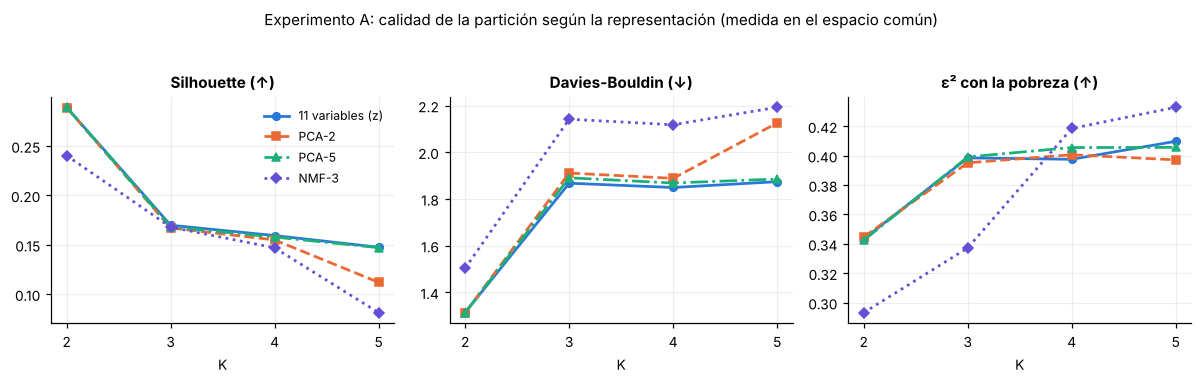

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(11, 3.3))
estilos = {"11 variables (z)": ("#2a78d6", "o", "-"), "PCA-2": ("#eb6834", "s", "--"),
           "PCA-5": ("#1baf7a", "^", "-."), "NMF-3": ("#6250d6", "D", ":")}
for rep, (c, mk, ls) in estilos.items():
    d = resA[resA["representación"] == rep]
    for a, col, tt in zip(ax, ["silhouette", "davies_bouldin", "eps2_pobreza"],
                          ["Silhouette (↑)", "Davies-Bouldin (↓)", "ε² con la pobreza (↑)"]):
        a.plot(d["K"], d[col], color=c, marker=mk, ls=ls, lw=1.8, ms=5, label=rep); a.set(title=tt, xlabel="K", xticks=list(K_RANGO))
ax[0].legend(fontsize=8)
fig.suptitle("Experimento A: calidad de la partición según la representación (medida en el espacio común)", y=1.04, fontsize=10)
guardar(fig, "h3_01_experimento_A.png")

**Lectura del experimento A.** La representación casi no cambia la partición, y ninguna alternativa mejora a las 11 variables.

- **PCA-5 reproduce la solución base.** Con K = 3 obtiene silhouette 0.168 (frente a 0.170), ε² 0.399 (frente a 0.398) y un ARI de 0.955 con la partición de las 11 variables. Cinco componentes retienen 81.5 % de la varianza, pero la distancia euclidiana en ese subespacio es casi la misma que en el espacio completo.
- **PCA-2 pierde detalle.** Con solo 56.3 % de la varianza el ARI baja a 0.863 y, desde K = 5, se vuelve inestable (silhouette 0.112, ARI bootstrap 0.752).
- **NMF-3 es peor con K = 3.** Davies-Bouldin 2.14 (frente a 1.87), ε² 0.337 (frente a 0.398), un grupo mínimo de 222 distritos y un ARI de solo 0.524 con la base. En el Hito 2, el NMF con k = 2 ya mostraba una correlación de −0.97 entre sus dos factores, es decir, casi un solo eje.
- **Decisión:** se trabaja con las **11 variables estandarizadas**: no pierden información, sus centroides se leen en unidades originales y la reducción no aporta evidencia a favor. El PCA se conserva para visualizar (figura de la sección 9).

*Nota:* una silhouette de 0.17 con K = 3 ya anticipa que la estructura de los datos es débil; se discute en las secciones 6 y 11.

## 6. Experimento B — elección de K en K-means (K = 2…6, 11 variables)

Se miran en conjunto la **inercia** (codo), las tres métricas internas, el criterio externo (ε² con la pobreza), la estabilidad
(ARI bootstrap) y el tamaño del grupo más pequeño. K no se decide con una sola métrica.

In [9]:
K_B = range(2, 7)
inercias = {1: KMeans(1, n_init=1, random_state=SEMILLA).fit(Xs).inertia_}
filasB, etiquetas_B = [], {}
for k in K_B:
    km_ = KMeans(k, n_init=10, random_state=SEMILLA).fit(Xs)
    inercias[k] = km_.inertia_; etiquetas_B[k] = km_.labels_
    filasB.append({"inercia": km_.inertia_, **evaluar(km_.labels_, Xs)})
resB = pd.DataFrame(filasB)
resB["caída_inercia_%"] = [100 * (inercias[k - 1] - inercias[k]) / inercias[k - 1] for k in K_B]
resB = resB[["K", "inercia", "caída_inercia_%", "silhouette", "davies_bouldin", "calinski_harabasz",
             "eps2_pobreza", "ari_bootstrap", "tam_min"]]
resB.to_csv(TAB / "t03_experimento_B_kmeans_K.csv", index=False, encoding="utf-8-sig")
print("Inercia K=1:", round(inercias[1]))
display(resB.round(3).set_index("K"))

Inercia K=1: 13970


,inercia,caída_inercia_%,silhouette,davies_bouldin,calinski_harabasz,eps2_pobreza,ari_bootstrap,tam_min
K,,,,,,,,
2,9347.764,33.087,0.289,1.314,626.994,0.343,0.988,557
3,8422.373,9.900,0.170,1.867,417.272,0.398,0.953,343
4,7790.465,7.503,0.159,1.849,334.738,0.398,0.829,157
5,7271.389,6.663,0.148,1.874,291.339,0.410,0.871,113
6,6906.261,5.021,0.128,1.875,258.564,0.399,0.733,116


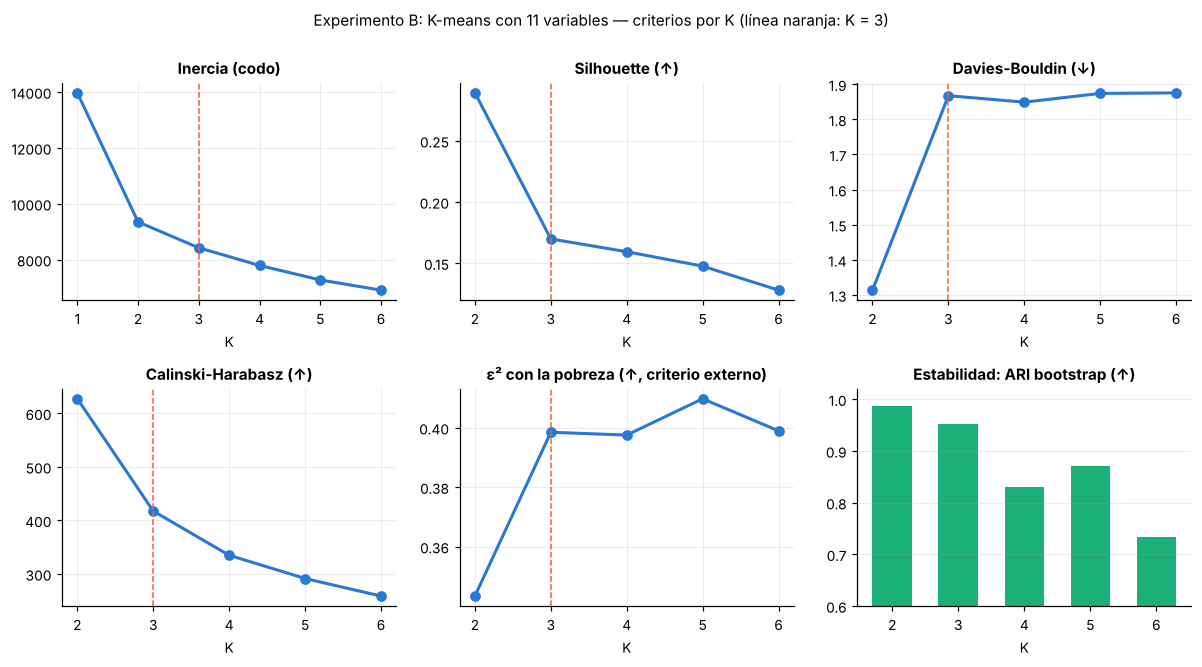

In [10]:
fig, ax = plt.subplots(2, 3, figsize=(11, 6))
ks = list(K_B)
ax[0, 0].plot([1] + ks, [inercias[k] for k in [1] + ks], color=COL[1], marker="o", lw=2)
ax[0, 0].set(title="Inercia (codo)", xlabel="K", xticks=[1] + ks)
for a, col, tt in zip(ax.ravel()[1:5], ["silhouette", "davies_bouldin", "calinski_harabasz", "eps2_pobreza"],
                      ["Silhouette (↑)", "Davies-Bouldin (↓)", "Calinski-Harabasz (↑)", "ε² con la pobreza (↑, criterio externo)"]):
    a.plot(resB["K"], resB[col], color=COL[1], marker="o", lw=2); a.set(title=tt, xlabel="K", xticks=ks)
    a.axvline(3, color=COL[3], ls="--", lw=1);
ax[1, 2].bar(resB["K"], resB["ari_bootstrap"], color=COL[2], width=.6)
ax[1, 2].set(title="Estabilidad: ARI bootstrap (↑)", xlabel="K", xticks=ks, ylim=(.6, 1.02)); ax[1, 2].grid(axis="x", alpha=0)
ax[0, 0].axvline(3, color=COL[3], ls="--", lw=1)
fig.suptitle("Experimento B: K-means con 11 variables — criterios por K (línea naranja: K = 3)", y=1.0, fontsize=10)
guardar(fig, "h3_02_experimento_B_K.png")

In [11]:
# ¿Qué ocurre al pasar de K=3 a K=4? (qué grupo se parte)
k3, k4 = etiquetas_B[3], etiquetas_B[4]
orden3 = pd.Series(X["pct_rural"].to_numpy()).groupby(k3).mean().sort_values().index
ren3 = {c: i + 1 for i, c in enumerate(orden3)}
orden4 = pd.Series(X["pct_rural"].to_numpy()).groupby(k4).mean().sort_values().index
ren4 = {c: i + 1 for i, c in enumerate(orden4)}
cruce = pd.crosstab(pd.Series(k3).map(ren3).rename("K=3"), pd.Series(k4).map(ren4).rename("K=4"))
display(cruce)
perfil4 = X.assign(c=pd.Series(k4).map(ren4).to_numpy()).groupby("c")[["pct_rural", "tasa_subempleo_horas_pct", "tasa_informalidad_pct", "pct_asalariados"]].mean().round(1)
perfil4["n"] = np.bincount(pd.Series(k4).map(ren4))[1:]
display(perfil4)

K=4,1,2,3,4
K=3,,,,
1,270,73,0,0
2,0,319,45,66
3,0,0,112,385


,pct_rural,tasa_subempleo_horas_pct,tasa_informalidad_pct,pct_asalariados,n
c,,,,,
1,11.7,7.5,56.7,59.3,270
2,42.8,6.2,81.2,43.2,392
3,88.6,25.4,94.5,24.2,157
4,90.5,3.2,97.0,18.9,451


**Lectura del experimento B.** Los criterios no apuntan al mismo K, y eso es parte del resultado.

- **Inercia.** Cae 33.1 % al pasar de K = 1 a 2, 9.9 % a K = 3 y luego 7.5 %, 6.7 % y 5.0 %: casi en línea recta. No hay un codo nítido más allá de K = 2.
- **Criterios internos.** Los tres favorecen **K = 2** (silhouette 0.289, Davies-Bouldin 1.31, Calinski-Harabasz 627), y con K = 3 caen a 0.170, 1.87 y 417. Una silhouette de 0.17 indica estructura débil: los distritos forman más un **gradiente continuo** que grupos separados.
- **Criterio externo (pobreza, no usada para agrupar).** ε² sube de 0.343 (K = 2) a **0.398 (K = 3)** y después se aplana: 0.398 (K = 4), 0.410 (K = 5), 0.399 (K = 6). K = 3 captura casi toda la asociación con la pobreza que se logra con más grupos.
- **Estabilidad.** ARI bootstrap de 0.988 (K = 2) y **0.953 (K = 3)**; con K ≥ 4 baja a 0.829, 0.871 y 0.733.
- **K = 4 no es una subdivisión limpia de K = 3.** Introduce un grupo de alto subempleo (157 distritos, 25.4 % de subempleo por horas) formado por 112 distritos del grupo rural y 45 del mixto, y mueve 73 distritos del grupo urbano al segundo. El otro grupo rural (451 distritos) tiene 3.2 % de subempleo, con rural 90.5 % e informalidad 97.0 %; es decir, la diferencia entre los dos grupos rurales es el subempleo.

**Decisión provisional:** **K = 3** es el K más pequeño que recoge la mayor parte de la relación con la pobreza con una partición estable. No se presenta como «óptimo»: K = 2 es estadísticamente más limpio (pero solo separa rural de urbano) y K = 4 queda abierto como alternativa para el Hito 4 por su grupo de subempleo.

## 7. Experimento C — alternativas: jerárquico (Ward) y DBSCAN

### 7.1 Jerárquico con Ward (K = 2…6) y otros enlaces

In [12]:
filasW, etiquetas_W = [], {}
for k in range(2, 7):
    lab = AgglomerativeClustering(k, linkage="ward").fit_predict(Xs); etiquetas_W[k] = lab
    filasW.append({"método": "Ward", **evaluar(lab, Xs, algo="ward")})
resW = pd.DataFrame(filasW)
resW.to_csv(TAB / "t04_experimento_C_ward.csv", index=False, encoding="utf-8-sig")
display(resW.round(3).set_index("K"))

enlaces = []
for enl in ["ward", "complete", "average", "single"]:
    lab = fcluster(linkage(Xs, method=enl), 3, criterion="maxclust")
    enlaces.append({"enlace": enl, "tamaños (K=3)": " / ".join(map(str, sorted(np.bincount(lab)[1:], reverse=True))),
                    "grupo más chico": int(np.bincount(lab)[1:].min())})
tabla_enlaces = pd.DataFrame(enlaces).set_index("enlace"); display(tabla_enlaces)
tabla_enlaces.to_csv(TAB / "t05_enlaces_K3.csv", encoding="utf-8-sig")

,método,ruido_%,tam_min,silhouette,davies_bouldin,calinski_harabasz,eps2_pobreza,ari_bootstrap
K,,,,,,,,
2,Ward,0.0,399,0.268,1.290,529.916,0.282,0.483
3,Ward,0.0,258,0.130,2.090,356.167,0.358,0.546
4,Ward,0.0,151,0.120,2.146,281.301,0.369,0.453
5,Ward,0.0,151,0.110,2.295,236.145,0.369,0.395
6,Ward,0.0,47,0.095,2.181,209.123,0.378,0.361


,tamaños (K=3),grupo más chico
enlace,,
ward,613 / 399 / 258,258
complete,1101 / 111 / 58,58
average,1266 / 2 / 2,2
single,1268 / 1 / 1,1


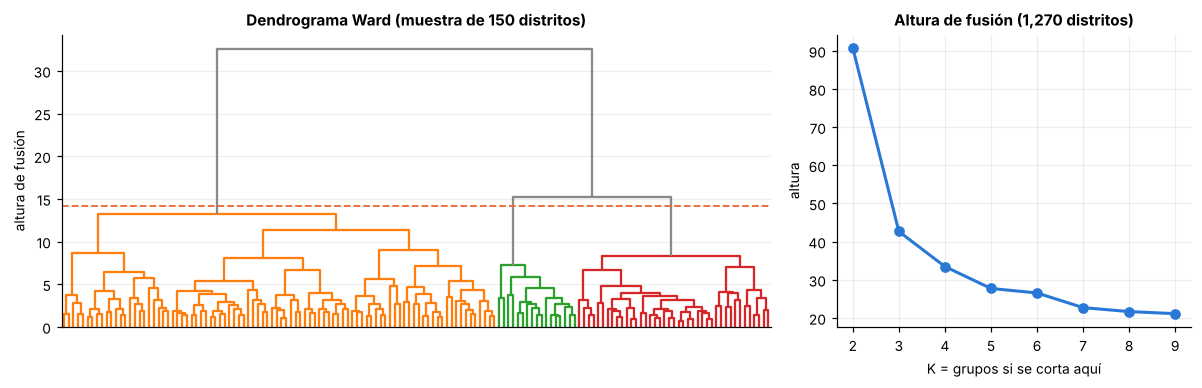

K,2,3,4,5,6,7,8,9
altura,90.7,42.7,33.5,27.7,26.6,22.7,21.7,21.1
salto_vs_siguiente,48.1,9.2,5.7,1.2,3.8,1.0,0.5,1.6


In [13]:
# Dendrograma Ward sobre una muestra reproducible de 150 distritos (solo para ver el árbol)
idx = np.random.default_rng(SEMILLA).choice(len(Xs), 150, replace=False)
Zm = linkage(Xs[idx], "ward"); corte = (Zm[-3, 2] + Zm[-2, 2]) / 2
Zf = linkage(Xs, "ward"); h = Zf[::-1, 2]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [2, 1]})
dendrogram(Zm, ax=ax[0], no_labels=True, color_threshold=corte, above_threshold_color=GRIS)
ax[0].axhline(corte, color=COL[3], ls="--", lw=1.2); ax[0].set(title="Dendrograma Ward (muestra de 150 distritos)", ylabel="altura de fusión"); ax[0].grid(axis="x", alpha=0)
ax[1].plot(range(2, 10), h[:8], color=COL[1], marker="o", lw=2); ax[1].set(title="Altura de fusión (1,270 distritos)", xlabel="K = grupos si se corta aquí", ylabel="altura")
saltos = pd.DataFrame({"K": range(2, 10), "altura": h[:8], "salto_vs_siguiente": h[:8] - h[1:9]}).set_index("K")
guardar(fig, "h3_03_dendrograma_ward.png"); display(saltos.round(1).T)

### 7.2 DBSCAN: rejilla de `eps` × `min_samples` en dos representaciones

`min_samples` se prueba en 11 (= número de variables), 22 (= 2 × variables, regla práctica) y 33. `eps` se barre alrededor del codo
del gráfico de k-distancias (distancia al vecino número `min_samples`).

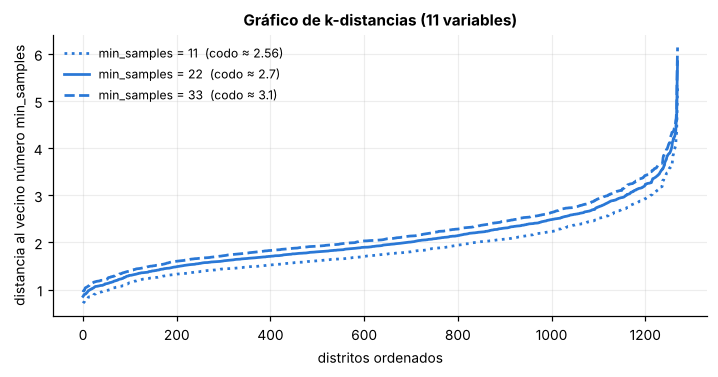

Codos: {11: 2.56, 22: 2.7, 33: 3.1}


In [14]:
fig, ax = plt.subplots(figsize=(6.6, 3.5)); codos = {}
for ms, ls in zip([11, 22, 33], [":", "-", "--"]):
    kd = np.sort(NearestNeighbors(n_neighbors=ms).fit(Xs).kneighbors(Xs)[0][:, -1])
    x = np.linspace(0, 1, len(kd)); y = (kd - kd.min()) / (kd.max() - kd.min()); codos[ms] = round(float(kd[np.argmax(x - y)]), 2)
    ax.plot(kd, color=COL[1], ls=ls, lw=1.8, label=f"min_samples = {ms}  (codo ≈ {codos[ms]})")
ax.set(title="Gráfico de k-distancias (11 variables)", xlabel="distritos ordenados", ylabel="distancia al vecino número min_samples"); ax.legend(fontsize=8)
guardar(fig, "h3_04_kdistancias.png"); print("Codos:", codos)

In [15]:
filasD, etiquetas_D = [], {}
for rep in ["11 variables (z)", "PCA-5"]:
    A = REPS[rep]
    for ms in [11, 22, 33]:
        for eps in [1.0, 1.5, 2.0, 2.5, 2.7, 3.0]:
            lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(A); etiquetas_D[(rep, ms, eps)] = lab
            nk = len(set(lab)) - (1 if -1 in lab else 0)
            filasD.append({"representación": rep, "min_samples": ms, "eps": eps, "clusters": nk,
                           "ruido_%": round(100 * (lab == -1).mean(), 1),
                           "grupo_mayor_%": round(100 * np.bincount(lab[lab >= 0]).max() / len(lab), 1) if nk else 0})
resD = pd.DataFrame(filasD)
resD.to_csv(TAB / "t06_experimento_C_dbscan.csv", index=False, encoding="utf-8-sig")
display(resD.pivot_table(index=["representación", "min_samples"], columns="eps", values=["clusters", "ruido_%"]).round(1))
print("Configuraciones con ≥ 2 clusters y ruido < 20 %:", int(((resD["clusters"] >= 2) & (resD["ruido_%"] < 20)).sum()), "de", len(resD))
display(resD[resD["clusters"] >= 2])

clusters                          ruido_%        \
eps                               1.0  1.5  2.0  2.5  2.7  3.0     1.0   1.5   
representación   min_samples                                                   
11 variables (z) 11               1.0  1.0  1.0  1.0  1.0  1.0    90.8  45.9   
                 22               1.0  1.0  1.0  1.0  1.0  1.0    93.5  58.5   
                 33               1.0  2.0  1.0  1.0  1.0  1.0    95.6  68.9   
PCA-5            11               1.0  1.0  1.0  1.0  1.0  1.0    35.9   7.6   
                 22               1.0  1.0  1.0  1.0  1.0  1.0    54.2  10.9   
                 33               2.0  1.0  1.0  1.0  1.0  1.0    71.9  14.5   

                                                   
eps                            2.0  2.5  2.7  3.0  
representación   min_samples                       
11 variables (z) 11           15.2  3.7  1.9  0.9  
                 22           18.5  5.4  2.7  0.9  
                 33           21.8  6.3  3.5  1.3  
PCA-5            11            1.4  0.4  0.3  0.2  
                 22            2.2  0.6  0.4  0.2  
                 33            2.7  0.6  0.5  0.2

Configuraciones con ≥ 2 clusters y ruido < 20 %: 0 de 36


,representación,min_samples,eps,clusters,ruido_%,grupo_mayor_%
13,11 variables (z),33,1.5,2,68.9,24.0
30,PCA-5,33,1.0,2,71.9,18.6


In [16]:
# ¿Quiénes son los 34 distritos de ruido con el eps del codo (11 variables, eps = 2.7, min_samples = 22)?
ruido = etiquetas_D[("11 variables (z)", 22, 2.7)] == -1
cmp_ruido = pd.DataFrame({"distritos": [ruido.sum(), (~ruido).sum()],
                          "encuestados (mediana)": [matriz.loc[ruido, "n_muestra"].median(), matriz.loc[~ruido, "n_muestra"].median()],
                          "con n < 10 (%)": [100 * (matriz.loc[ruido, "n_muestra"] < 10).mean(), 100 * (matriz.loc[~ruido, "n_muestra"] < 10).mean()]},
                         index=["ruido", "cluster 1"]).round(1)
display(cmp_ruido)

,distritos,encuestados (mediana),con n < 10 (%)
ruido,34,9.0,55.9
cluster 1,1236,24.0,7.0


**Lectura del experimento C.**

**Ward.** A igual K rinde menos que K-means: con K = 3 tiene silhouette 0.130 (frente a 0.170), ε² 0.358 (frente a 0.398) y, sobre todo, una estabilidad baja (ARI bootstrap 0.546 frente a 0.953). El salto de altura más grande está en K = 2 (48.1) y el siguiente en K = 3 (9.2); desde K = 4 los saltos son ≤ 5.7. Los otros enlaces producen particiones degeneradas con K = 3: *complete* 1,101 / 111 / 58, *average* 1,266 / 2 / 2 y *single* 1,268 / 1 / 1 (encadenamiento).

**DBSCAN.** Ninguna de las 36 configuraciones probadas (2 representaciones × 3 `min_samples` × 6 `eps`) produce ≥ 2 clusters con menos de 20 % de ruido. Las dos que producen 2 clusters dejan 68.9 % y 71.9 % de ruido. Con el `eps` del codo (2.7; `min_samples` = 22) hay **un solo cluster** y 34 distritos de ruido (2.7 %). Los distritos forman una nube continua sin valles de densidad entre perfiles, así que DBSCAN no tiene dónde cortar. Su ruido sí sirve como detector de distritos poco confiables: los 34 distritos de ruido tienen una mediana de 9 encuestados (frente a 24 en el cluster) y 55.9 % de ellos tiene menos de 10 (frente a 7.0 %).

## 8. Comparación final y técnica seleccionada

Se juntan las configuraciones candidatas en una sola tabla, evaluadas con los mismos criterios en el mismo espacio.
`ARI vs. K-means K=3` mide cuánto se parece cada partición a la de K-means con K = 3.

In [17]:
cands = {
    "K-means K=2":              (etiquetas_B[2], "kmeans"),
    "K-means K=3":              (etiquetas_B[3], "kmeans"),
    "K-means K=4":              (etiquetas_B[4], "kmeans"),
    "Ward K=2":                 (etiquetas_W[2], "ward"),
    "Ward K=3":                 (etiquetas_W[3], "ward"),
    "Ward K=4":                 (etiquetas_W[4], "ward"),
    "DBSCAN eps=2.7, ms=22":    (etiquetas_D[("11 variables (z)", 22, 2.7)], None),
}
ref = etiquetas_B[3]
filasF = []
for nombre, (lab, algo) in cands.items():
    r = evaluar(lab, Xs, algo=algo or "kmeans", boot=algo is not None)
    r["ARI vs K-means K=3"] = adjusted_rand_score(ref, lab) if nombre != "DBSCAN eps=2.7, ms=22" else np.nan
    filasF.append({"configuración": nombre, **r})
resF = pd.DataFrame(filasF).set_index("configuración")
resF.to_csv(TAB / "t07_comparacion_final.csv", encoding="utf-8-sig")
display(resF.round(3))

,K,ruido_%,tam_min,silhouette,davies_bouldin,calinski_harabasz,eps2_pobreza,ari_bootstrap,ARI vs K-means K=3
configuración,,,,,,,,,
K-means K=2,2,0.0,557,0.289,1.314,626.994,0.343,0.988,0.439
K-means K=3,3,0.0,343,0.170,1.867,417.272,0.398,0.953,1.000
K-means K=4,4,0.0,157,0.159,1.849,334.738,0.398,0.829,0.553
Ward K=2,2,0.0,399,0.268,1.290,529.916,0.282,0.483,0.406
Ward K=3,3,0.0,258,0.130,2.090,356.167,0.358,0.546,0.524
Ward K=4,4,0.0,151,0.120,2.146,281.301,0.369,0.453,0.417
"DBSCAN eps=2.7, ms=22",1,2.7,1236,NaN,NaN,NaN,NaN,NaN,NaN


**Técnica seleccionada: K-means con K = 3 sobre las 11 variables laborales estandarizadas.**

1. **Responde el objetivo.** Produce una partición completa de los distritos con centroides legibles en unidades originales, que es lo que necesita el MTPE para describir perfiles.
2. **Es la más estable.** ARI bootstrap de 0.953 frente a 0.546 de Ward K = 3; DBSCAN no produce partición.
3. **Es la que más se asocia con la pobreza sin usarla:** ε² = 0.398, frente a 0.358 de Ward K = 3, y casi igual al máximo alcanzado con más grupos.
4. **Ward y DBSCAN se descartan con evidencia**, no por preferencia: Ward es inestable y más débil en todos los criterios; DBSCAN no encuentra estructura de densidad.
5. **Reconoce sus límites:** silhouette 0.170 (estructura débil), K no unívoco (K = 2 gana en criterios internos) y un solo eje dominante rural-urbano. Los grupos son una **segmentación útil de un gradiente continuo**, no «clases naturales».

Ward K = 3 coincide con K-means en los extremos pero no en el grupo intermedio (ARI 0.524); se mantiene como contraste para el Hito 4.

## 9. Primeros resultados — K-means con K = 3 sobre las 11 variables

Se ajusta la técnica seleccionada y se renumeran los clusters de menor a mayor % rural para que 1, 2 y 3 siempre signifiquen lo
mismo. Los nombres son **etiquetas descriptivas provisionales**, no categorías oficiales.

In [18]:
K_FINAL = 3
km = KMeans(K_FINAL, n_init=10, random_state=SEMILLA).fit(Xs)
orden = pd.Series(X["pct_rural"].to_numpy()).groupby(km.labels_).mean().sort_values().index
cluster = pd.Series(km.labels_).map({c: i + 1 for i, c in enumerate(orden)}).to_numpy()
NOMBRES = {1: "Urbano asalariado", 2: "Mixto de transición", 3: "Rural agropecuario"}
datos = matriz.assign(cluster_kmeans=cluster)

tam = pd.Series(cluster).value_counts().sort_index()
display(pd.DataFrame({"perfil": tam.index.map(NOMBRES), "distritos": tam.values, "% de distritos": (100 * tam / tam.sum()).round(1).values,
                      "población 2020 (millones)": (datos.groupby("cluster_kmeans")["POBLACION_2020"].sum() / 1e6).round(2).values},
                     index=pd.Index(tam.index, name="cluster")))

,perfil,distritos,% de distritos,población 2020 (millones)
cluster,,,,
1,Urbano asalariado,343,27.0,23.01
2,Mixto de transición,430,33.9,5.48
3,Rural agropecuario,497,39.1,2.84


In [19]:
UNIDADES = {"tasa_informalidad_pct": "Informalidad (%)", "tasa_subempleo_horas_pct": "Subempleo por horas (%)",
            "ingreso_mensual_w": "Ingreso mensual (S/)", "horas_promedio_semana": "Horas por semana",
            "nivel_educativo_promedio": "Nivel educativo (1–11)", "tamano_empresa_promedio": "Tamaño de empresa (1–5)",
            "pct_rural": "Rural (%)", "pct_agropecuario": "Agro (%)", "pct_asalariados": "Asalariados (%)",
            "pct_mujeres": "Mujeres (%)", "edad_promedio": "Edad (años)"}
perfil = datos.groupby("cluster_kmeans")[list(UNIDADES)].mean().T
perfil["Total"] = matriz[list(UNIDADES)].mean(); perfil.index = perfil.index.map(UNIDADES)
perfil.columns = [f"{c}. {NOMBRES[c]}" if c in NOMBRES else c for c in perfil.columns]
display(perfil.round(1)); perfil.round(2).to_csv(TAB / "t08_perfil_clusters.csv", encoding="utf-8-sig")

# Variables NO usadas en el clustering: lectura externa
ext = datos.groupby("cluster_kmeans").agg(pobreza_media=("pobreza_pct", "mean"), pobreza_mediana=("pobreza_pct", "median"),
                                          pobreza_p25=("pobreza_pct", lambda s: s.quantile(.25)), pobreza_p75=("pobreza_pct", lambda s: s.quantile(.75)),
                                          encuestados_mediana=("n_muestra", "median"), ingresos_imputados=("ingreso_imputado", "sum"))
ext.round(1).to_csv(TAB / "t09_lectura_externa.csv", encoding="utf-8-sig"); display(ext.round(1))
print(f"ε² (Kruskal-Wallis) de la pobreza según el cluster: {eps2_pobreza(cluster):.3f}")
print("\nRegión natural (% de distritos de cada cluster):")
reg = pd.crosstab(datos["cluster_kmeans"], datos["region_natural"], normalize="index").mul(100).round(0); display(reg)
reg.to_csv(TAB / "t10_region_por_cluster.csv", encoding="utf-8-sig")

,1. Urbano asalariado,2. Mixto de transición,3. Rural agropecuario,Total
Informalidad (%),60.3,84.9,97.7,83.3
Subempleo por horas (%),7.2,7.5,8.4,7.8
Ingreso mensual (S/),1854.0,1324.2,854.5,1306.6
Horas por semana,41.7,37.6,32.0,36.5
Nivel educativo (1–11),6.7,5.5,4.6,5.5
Tamaño de empresa (1–5),2.0,1.5,1.1,1.5
Rural (%),13.2,55.1,93.4,58.8
Agro (%),16.7,47.1,80.0,51.8
Asalariados (%),56.9,39.5,17.6,35.6
Mujeres (%),42.6,40.3,41.5,41.4


,pobreza_media,pobreza_mediana,pobreza_p25,pobreza_p75,encuestados_mediana,ingresos_imputados
cluster_kmeans,,,,,,
1,16.7,15.1,7.5,22.6,50.0,0
2,32.0,31.0,21.7,42.9,26.0,2
3,43.9,44.3,35.4,53.0,16.0,65


ε² (Kruskal-Wallis) de la pobreza según el cluster: 0.398

Región natural (% de distritos de cada cluster):


region_natural,Costa,Lima Metropolitana,Selva,Sierra
cluster_kmeans,,,,
1,45.0,13.0,8.0,34.0
2,20.0,0.0,25.0,54.0
3,5.0,0.0,20.0,75.0


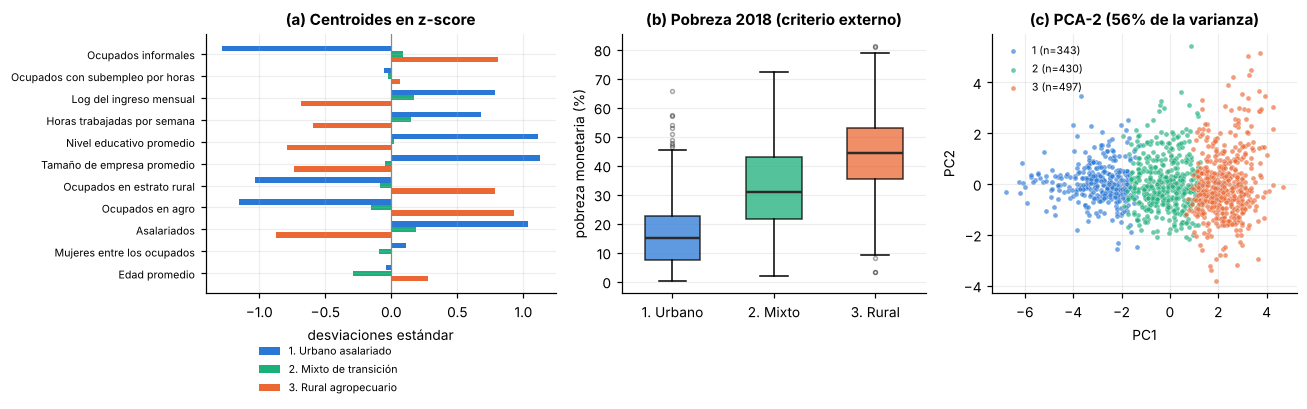

In [20]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.9), gridspec_kw={"width_ratios": [1.15, 1, 1]})
# (a) Perfil en z-score (centroides) — qué distingue a cada grupo
cz = pd.DataFrame(Xs, columns=VARS).groupby(cluster).mean().T; cz.index = [UNIDADES.get(v, v) if v in UNIDADES else v for v in cz.index]
cz.index = [DESCRIPCION[v].split(" (")[0].split(",")[0] for v in VARS]
yy = np.arange(len(VARS))
for c, off in zip([1, 2, 3], [-.25, 0, .25]):
    ax[0].barh(yy + off, cz[c], height=.24, color=COL[c], label=f"{c}. {NOMBRES[c]}")
ax[0].set_yticks(yy, cz.index, fontsize=7); ax[0].invert_yaxis(); ax[0].axvline(0, color=GRIS, lw=.8)
ax[0].set(title="(a) Centroides en z-score", xlabel="desviaciones estándar"); ax[0].legend(fontsize=7, loc="upper center", bbox_to_anchor=(.35, -.16), ncol=1)
# (b) Pobreza por cluster (no usada para agrupar)
ax[1].boxplot([datos.loc[datos.cluster_kmeans == c, "pobreza_pct"] for c in (1, 2, 3)], widths=.55, patch_artist=True,
              medianprops=dict(color=TINTA, lw=1.6), flierprops=dict(marker="o", ms=2.5, alpha=.35))
for p, c in zip(ax[1].patches, (1, 2, 3)): p.set(facecolor=COL[c], alpha=.75)
ax[1].set_xticks([1, 2, 3], ["1. Urbano", "2. Mixto", "3. Rural"]); ax[1].set(title="(b) Pobreza 2018 (criterio externo)", ylabel="pobreza monetaria (%)"); ax[1].grid(axis="x", alpha=0)
# (c) Plano de las 2 primeras componentes
Z2 = REPS["PCA-2"]
for c in (1, 2, 3):
    m_ = cluster == c; ax[2].scatter(Z2[m_, 0], Z2[m_, 1], s=11, alpha=.65, color=COL[c], edgecolor="white", linewidth=.3, label=f"{c} (n={m_.sum()})")
ax[2].set(title=f"(c) PCA-2 ({var_acum[1]:.0%} de la varianza)", xlabel="PC1", ylabel="PC2"); ax[2].legend(fontsize=7)
guardar(fig, "h3_05_resultados_kmeans_k3.png")

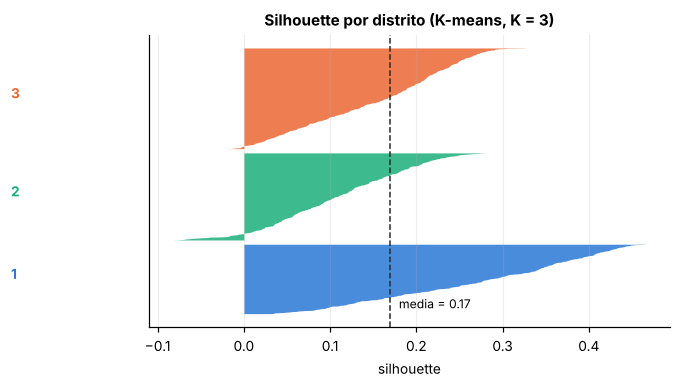

,silhouette medio
1,0.272
2,0.109
3,0.152


Distritos con silhouette < 0 (posible mala asignación): 46 (3.6 %)


In [21]:
# Silhouette por distrito: ¿qué tan bien asignado está cada uno?
s = silhouette_samples(Xs, cluster)
fig, ax = plt.subplots(figsize=(6.3, 3.6)); y0 = 0
for c in (1, 2, 3):
    v = np.sort(s[cluster == c]); ax.fill_betweenx(np.arange(y0, y0 + len(v)), 0, v, color=COL[c], alpha=.85, linewidth=0)
    ax.text(-.27, y0 + len(v) / 2, f"{c}", color=COL[c], fontweight="bold"); y0 += len(v) + 20
ax.axvline(s.mean(), color=TINTA, ls="--", lw=1); ax.text(s.mean() + .01, y0 * .02, f"media = {s.mean():.2f}", fontsize=8)
ax.set(title="Silhouette por distrito (K-means, K = 3)", xlabel="silhouette", yticks=[]); ax.grid(axis="y", alpha=0)
guardar(fig, "h3_06_silhouette_por_distrito.png")
sil_cl = pd.Series(s).groupby(cluster).mean().round(3); display(sil_cl.to_frame("silhouette medio"))
print(f"Distritos con silhouette < 0 (posible mala asignación): {(s < 0).sum()} ({100*(s<0).mean():.1f} %)")

**Lectura de los primeros resultados** (preliminares; no son conclusiones finales).

- **Cluster 1 · Urbano asalariado (343 distritos, 23.0 M de habitantes).** Informalidad de 60.3 %, ingreso de S/ 1,854, 56.9 % asalariados, 13.2 % rural y 16.7 % en agro, con educación de 6.7 y empresas más grandes (2.0). Incluye 46 de los 47 distritos de Lima Metropolitana; por región natural, 45 % Costa, 13 % Lima Metropolitana, 34 % Sierra y 8 % Selva.
- **Cluster 2 · Mixto de transición (430, 5.5 M).** Informalidad de 84.9 %, ingreso de S/ 1,324, 55.1 % rural y 47.1 % en agro. Sierra 54 %, Selva 25 %, Costa 20 %. Es una zona de transición: su silhouette medio es el más bajo (0.109).
- **Cluster 3 · Rural agropecuario (497, 2.8 M).** Informalidad de 97.7 %, ingreso de S/ 855, 93.4 % rural y 80.0 % en agro, solo 17.6 % asalariados y la menor educación (4.6). Sierra 75 %.
- **Pobreza (no usada para formar los grupos).** La mediana sube de 15.1 % a 31.0 % y 44.3 % (medias 16.7 %, 32.0 % y 43.9 %), con ε² = 0.398: el perfil laboral explica cerca del 40 % de la variación en rangos de la pobreza distrital. Los rangos intercuartílicos se superponen entre grupos vecinos, así que la relación es de gradiente y no de corte.
- **Lo que no separa los grupos:** subempleo por horas (7.2 / 7.5 / 8.4 %), % de mujeres (42.6 / 40.3 / 41.5 %) y edad (41.5 / 40.2 / 43.1 años) son casi iguales en los tres. La segmentación recoge un eje (estructura productiva rural-urbana) y deja fuera otras dimensiones del empleo.
- **Calidad de la asignación.** Silhouette medio por cluster: 0.272, 0.109 y 0.152; 46 distritos (3.6 %) tienen silhouette negativo: 32 del grupo mixto, 14 del rural y ninguno del urbano, es decir, se concentran en la zona de transición.

## 10. Sensibilidad y robustez de la solución K = 3

Se comprueba cuánto cambia la partición si se cambia una decisión importante. **ARI = 1** significa partición idéntica;
valores bajos indican que la decisión importa.

In [22]:
def km3(A, n_init=10, seed=SEMILLA): return KMeans(3, n_init=n_init, random_state=seed).fit_predict(A)
filasS = []
# 1. Otras semillas
ari_sem = [adjusted_rand_score(cluster, km3(Xs, seed=s_)) for s_ in range(1, 11)]
filasS.append(("Otras 10 semillas (mín.)", min(ari_sem)))
# 2. Sin distritos con muestra chica (< 10 encuestados)
g10 = (matriz["n_muestra"] >= 10).to_numpy()
filasS.append((f"Sin los {(~g10).sum()} distritos con n < 10 encuestados", adjusted_rand_score(cluster[g10], km3(StandardScaler().fit_transform(X[g10])))))
# 3. Sin los distritos con ingreso imputado
gi = (matriz["ingreso_imputado"] == 0).to_numpy()
filasS.append((f"Sin los {(~gi).sum()} distritos con ingreso imputado", adjusted_rand_score(cluster[gi], km3(StandardScaler().fit_transform(X[gi])))))
# 4. Sin la variable de ingreso
sin_ing = [i for i, v in enumerate(VARS) if v != "log_ingreso_mensual"]
filasS.append(("Sin la variable de ingreso (10 variables)", adjusted_rand_score(cluster, km3(Xs[:, sin_ing]))))
# 5. Otro escalador
filasS.append(("RobustScaler en lugar de StandardScaler", adjusted_rand_score(cluster, km3(RobustScaler().fit_transform(X)))))
filasS.append(("MinMaxScaler en lugar de StandardScaler", adjusted_rand_score(cluster, km3(MinMaxScaler().fit_transform(X)))))
# 6. Otras representaciones / técnicas
filasS.append(("K-means sobre PCA-5", adjusted_rand_score(cluster, km3(REPS["PCA-5"]))))
filasS.append(("K-means sobre PCA-2", adjusted_rand_score(cluster, km3(REPS["PCA-2"]))))
filasS.append(("K-means sobre NMF-3", adjusted_rand_score(cluster, km3(REPS["NMF-3"]))))
filasS.append(("Ward con K = 3", adjusted_rand_score(cluster, etiquetas_W[3])))
sens = pd.DataFrame(filasS, columns=["cambio respecto de la solución base", "ARI vs. K-means K=3 (base)"]).set_index("cambio respecto de la solución base")
sens.round(3).to_csv(TAB / "t11_sensibilidad.csv", encoding="utf-8-sig"); display(sens.round(3))

# ¿Dónde caen los ingresos imputados?
print("Distribución de los distritos con ingreso imputado por cluster:", pd.Series(cluster[~gi]).value_counts().sort_index().to_dict())

,ARI vs. K-means K=3 (base)
cambio respecto de la solución base,
Otras 10 semillas (mín.),0.960
Sin los 105 distritos con n < 10 encuestados,0.956
Sin los 67 distritos con ingreso imputado,0.915
Sin la variable de ingreso (10 variables),0.881
RobustScaler en lugar de StandardScaler,0.363
MinMaxScaler en lugar de StandardScaler,0.575
K-means sobre PCA-5,0.955
K-means sobre PCA-2,0.863
K-means sobre NMF-3,0.524


Distribución de los distritos con ingreso imputado por cluster: {2: 2, 3: 65}


**Lectura de la sensibilidad.**

- **Robusta a perturbaciones de los datos:** otras semillas (ARI ≥ 0.960), quitar los 105 distritos con menos de 10 encuestados (0.956), quitar los 67 distritos con ingreso imputado (0.915) o prescindir de la variable de ingreso (0.881) casi no mueven la partición.
- **Robusta a la reducción de dimensión:** K-means sobre PCA-5 da ARI 0.955 y sobre PCA-2, 0.863.
- **Sensible al escalamiento y a la técnica:** `RobustScaler` (ARI 0.363), `MinMaxScaler` (0.575), NMF-3 (0.524) y Ward (0.524) producen particiones distintas. `RobustScaler` reduce el peso de `pct_rural` porque su IQR es muy amplio (distribución bimodal); `MinMaxScaler` depende de los extremos. Por eso la decisión de usar `StandardScaler` se declara y se justifica en el informe.
- **Ingresos imputados:** 65 de los 67 caen en el cluster 3, de modo que su ingreso medio (S/ 855) está algo influido por la imputación con la mediana; sin ellos la partición es casi igual (ARI 0.915).

## 11. Problemas encontrados y trabajo pendiente para el Hito 4

### 11.1 Problemas y limitaciones identificados

1. **Estructura continua.** Silhouette 0.17 con K = 3 (0.29 con K = 2): los distritos forman un gradiente rural-urbano y no grupos separados. DBSCAN lo confirma (no hay valles de densidad).
2. **K no es unívoco.** Los criterios internos prefieren K = 2; el criterio externo y la estabilidad respaldan K = 3; K = 4 aporta un grupo de alto subempleo con menor estabilidad. La elección de K es una decisión analítica que debe declararse.
3. **Sensibilidad al escalamiento.** `StandardScaler` frente a `RobustScaler` o `MinMaxScaler` cambia mucho la partición (ARI 0.36 y 0.58).
4. **Calidad de la muestra distrital.** 105 distritos tienen menos de 10 encuestados y el cluster 3 tiene una mediana de 16 encuestados por distrito (frente a 50 en el cluster 1); sus tasas son menos confiables. Hay además 67 ingresos imputados, 65 de ellos en el cluster 3.
5. **Desfase temporal.** La pobreza es de 2018 y el empleo de 2024 (6 años). La relación observada es una asociación, no una causalidad.
6. **Cobertura.** El cruce cubre 1,270 de los 1,873 distritos del mapa: los excluidos son distritos pequeños (población mediana 1,507 frente a 6,942), de modo que la segmentación no representa a los distritos más pequeños.
7. **Un solo eje.** Los grupos se explican casi por completo por el eje rural-urbano; subempleo, edad y % de mujeres no los distinguen.
8. **Criterio externo imperfecto.** ε² = 0.40 mide asociación con la pobreza 2018 estimada (con su propio error muestral), no «acierto».

### 11.2 Trabajo pendiente antes del Hito 4

- Evaluar **K = 2 y K = 4** de forma completa (perfilamiento, mapa) y decidir el K final con una regla explícita.
- Probar técnicas adicionales sobre la misma representación: **modelos de mezclas gaussianas** (asignación suave, útil para el grupo de transición) y **K-medoids**.
- Ponderar o filtrar según el **tamaño de muestra** distrital (por ejemplo, excluir n < 10 o ponderar por n) y repetir.
- Analizar el **grupo intermedio** y los 46 distritos de silhouette negativo.
- Contrastar el **desfase 2018-2024** con la pobreza departamental 2024 del INEI.
- Representar los grupos en **mapa** (GeoJSON distrital) y revisar su distribución territorial.
- Traducir los perfiles a **recomendaciones para el MTPE** y redactar discusión y conclusiones.
- Actualizar el README, agregar la sección del Hito 3 y publicar el enlace del repositorio en el PDF y en Blackboard.

## 12. Productos exportados

Se guarda la matriz con la etiqueta del Hito 3 (`cluster_kmeans_h3`), las etiquetas alternativas evaluadas (Ward, DBSCAN) y las tablas
`t01`…`t11` que alimentan el informe. Todo se regenera ejecutando el cuaderno de arriba abajo.

In [23]:
res = matriz.copy()
res["cluster_kmeans_h3"] = cluster
res["cluster_ward_k3"] = pd.Series(etiquetas_W[3]).map({c: i + 1 for i, c in enumerate(pd.Series(X["pct_rural"].to_numpy()).groupby(etiquetas_W[3]).mean().sort_values().index)}).to_numpy()
lab_db = etiquetas_D[("11 variables (z)", 22, 2.7)]; res["cluster_dbscan"] = np.where(lab_db >= 0, lab_db + 1, -1)
assert res["UBIGEO"].is_unique and res["cluster_kmeans_h3"].between(1, 3).all()
assert not {"cluster_kmeans_h3", "cluster_ward_k3", "cluster_dbscan"} & set(VARS)          # ninguna etiqueta fue insumo
res.to_csv(OUT / "resultados_hito3.csv", index=False, encoding="utf-8-sig")
print(f"output/resultados_hito3.csv: {res.shape[0]:,} × {res.shape[1]}")
print("Tablas:", sorted(p.name for p in TAB.glob("*.csv")))
print("Figuras Hito 3:", sorted(p.name for p in FIG.glob("h3_*.png")))

output/resultados_hito3.csv: 1,270 × 50
Tablas: ['t01_variables_representacion.csv', 't02_experimento_A_representaciones.csv', 't03_experimento_B_kmeans_K.csv', 't04_experimento_C_ward.csv', 't05_enlaces_K3.csv', 't06_experimento_C_dbscan.csv', 't07_comparacion_final.csv', 't08_perfil_clusters.csv', 't09_lectura_externa.csv', 't10_region_por_cluster.csv', 't11_sensibilidad.csv']
Figuras Hito 3: ['h3_01_experimento_A.png', 'h3_02_experimento_B_K.png', 'h3_03_dendrograma_ward.png', 'h3_04_kdistancias.png', 'h3_05_resultados_kmeans_k3.png', 'h3_06_silhouette_por_distrito.png']
